# Previsão de cancelamento de clientes de telecomunicações com redes neurais artificiais (MLP)

**Disciplina:** Modelagem de Dados com Redes Neurais Artificiais — USP · **Integrantes:** Rebeca Camille Bernardes, Ana Carolina Moraes Campos, Sabrina de Araújo Corrêa e Karen Dal Magro Frigeri

**Repositório:** [https://github.com/rebecabernardes89/churn-telco-mlp](https://github.com/rebecabernardes89/churn-telco-mlp) · [Abrir no Colab](https://colab.research.google.com/github/rebecabernardes89/churn-telco-mlp/blob/main/Churn_Telco_MLP.ipynb)

**Problema:** classificar se um cliente de uma operadora de telecomunicações vai cancelar o serviço (*churn*), a partir de dados cadastrais, de contrato e dos serviços contratados.

**Base:** *Telco Customer Churn* (IBM), disponível no Kaggle (`blastchar/telco-customer-churn`): 7.043 clientes, 19 variáveis explicativas e o alvo `Churn`.

**Rede:** perceptron multicamadas (MLP), adequado a dados tabulares de classificação binária.

**Roteiro do notebook**
1. Ambiente e reprodutibilidade
2. Carga dos dados
3. Análise exploratória
4. Divisão treino / validação / teste (60/20/20, estratificada)
5. Pré-processamento ajustado só no treino
6. Modelos de referência (classe majoritária e regressão logística)
7. MLP inicial, sem regularização
8. Busca aleatória de hiperparâmetros com validação cruzada
9. Contribuição de cada técnica (estudo de ablação)
10. Modelo final: conjunto de 5 redes e escolha do limiar na validação
11. Avaliação final no teste
12. Análise dos erros e importância das variáveis

**Tempo de execução:** cerca de 20 a 30 minutos em CPU no Google Colab (a maior parte na seção 8).

## 1. Ambiente e reprodutibilidade
As sementes são fixadas para que a execução possa ser repetida. As versões das bibliotecas são impressas para registro no relatório.

In [1]:
!pip install -q kagglehub

In [2]:
import os, time, random, warnings, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, tensorflow as tf
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
                             brier_score_loss)
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEMENTE = 42
keras.utils.set_random_seed(SEMENTE)       # fixa random, numpy e tensorflow
os.makedirs("figuras", exist_ok=True)
pd.set_option("display.width", 200)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| tensorflow/keras", tf.__version__, keras.__version__)

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | tensorflow/keras 2.21.0 3.15.1


## 2. Carga dos dados
O arquivo é baixado do Kaggle com `kagglehub`. Se o download falhar, usa-se a cópia pública do mesmo arquivo publicada pela IBM no GitHub.

In [3]:
def carregar():
    try:
        import kagglehub
        pasta = kagglehub.dataset_download("blastchar/telco-customer-churn")
        return pd.read_csv(os.path.join(pasta, "WA_Fn-UseC_-Telco-Customer-Churn.csv")), "Kaggle (kagglehub)"
    except Exception:
        url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
        return pd.read_csv(url), "GitHub da IBM (cópia pública)"

bruto, origem = carregar()
print("Origem:", origem, "| dimensões:", bruto.shape)
bruto.head()

Origem: GitHub da IBM (cópia pública) | dimensões: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Análise exploratória

### 3a. Tipos, ausentes e duplicidades
`TotalCharges` vem como texto porque 11 clientes têm o campo em branco. Todos eles têm `tenure = 0`, ou seja, acabaram de entrar e ainda não pagaram nenhuma fatura; o valor correto é 0, e não um dado a imputar.

In [4]:
print(bruto.dtypes.value_counts(), "\n")
tc = pd.to_numeric(bruto["TotalCharges"], errors="coerce")
print("TotalCharges em branco:", tc.isna().sum(), "| tenure desses clientes:", bruto.loc[tc.isna(), "tenure"].unique())
print("Ausentes nas demais colunas:", bruto.drop(columns="TotalCharges").isna().sum().sum())
print("IDs duplicados:", bruto["customerID"].duplicated().sum())
print("Linhas idênticas (ignorando o ID):", bruto.drop(columns="customerID").duplicated().sum())

str        18
int64       2
float64     1
Name: count, dtype: int64 

TotalCharges em branco: 11 | tenure desses clientes: [0]
Ausentes nas demais colunas: 0
IDs duplicados: 0
Linhas idênticas (ignorando o ID): 22


As 22 linhas idênticas pertencem a clientes diferentes (IDs distintos) com o mesmo perfil, e por isso foram mantidas.

### 3b. Distribuição da variável-alvo
Cerca de um quarto dos clientes cancelou: as classes são desbalanceadas, o que orienta a escolha das métricas (precisão, revocação, F1 e área sob a curva precisão-revocação, além da acurácia).

In [5]:
dist = bruto["Churn"].value_counts()
print(pd.DataFrame({"clientes": dist, "%": (dist / len(bruto) * 100).round(2)}))

       clientes      %
Churn                 
No         5174  73.46
Yes        1869  26.54


### 3c. Taxa de cancelamento por variável categórica

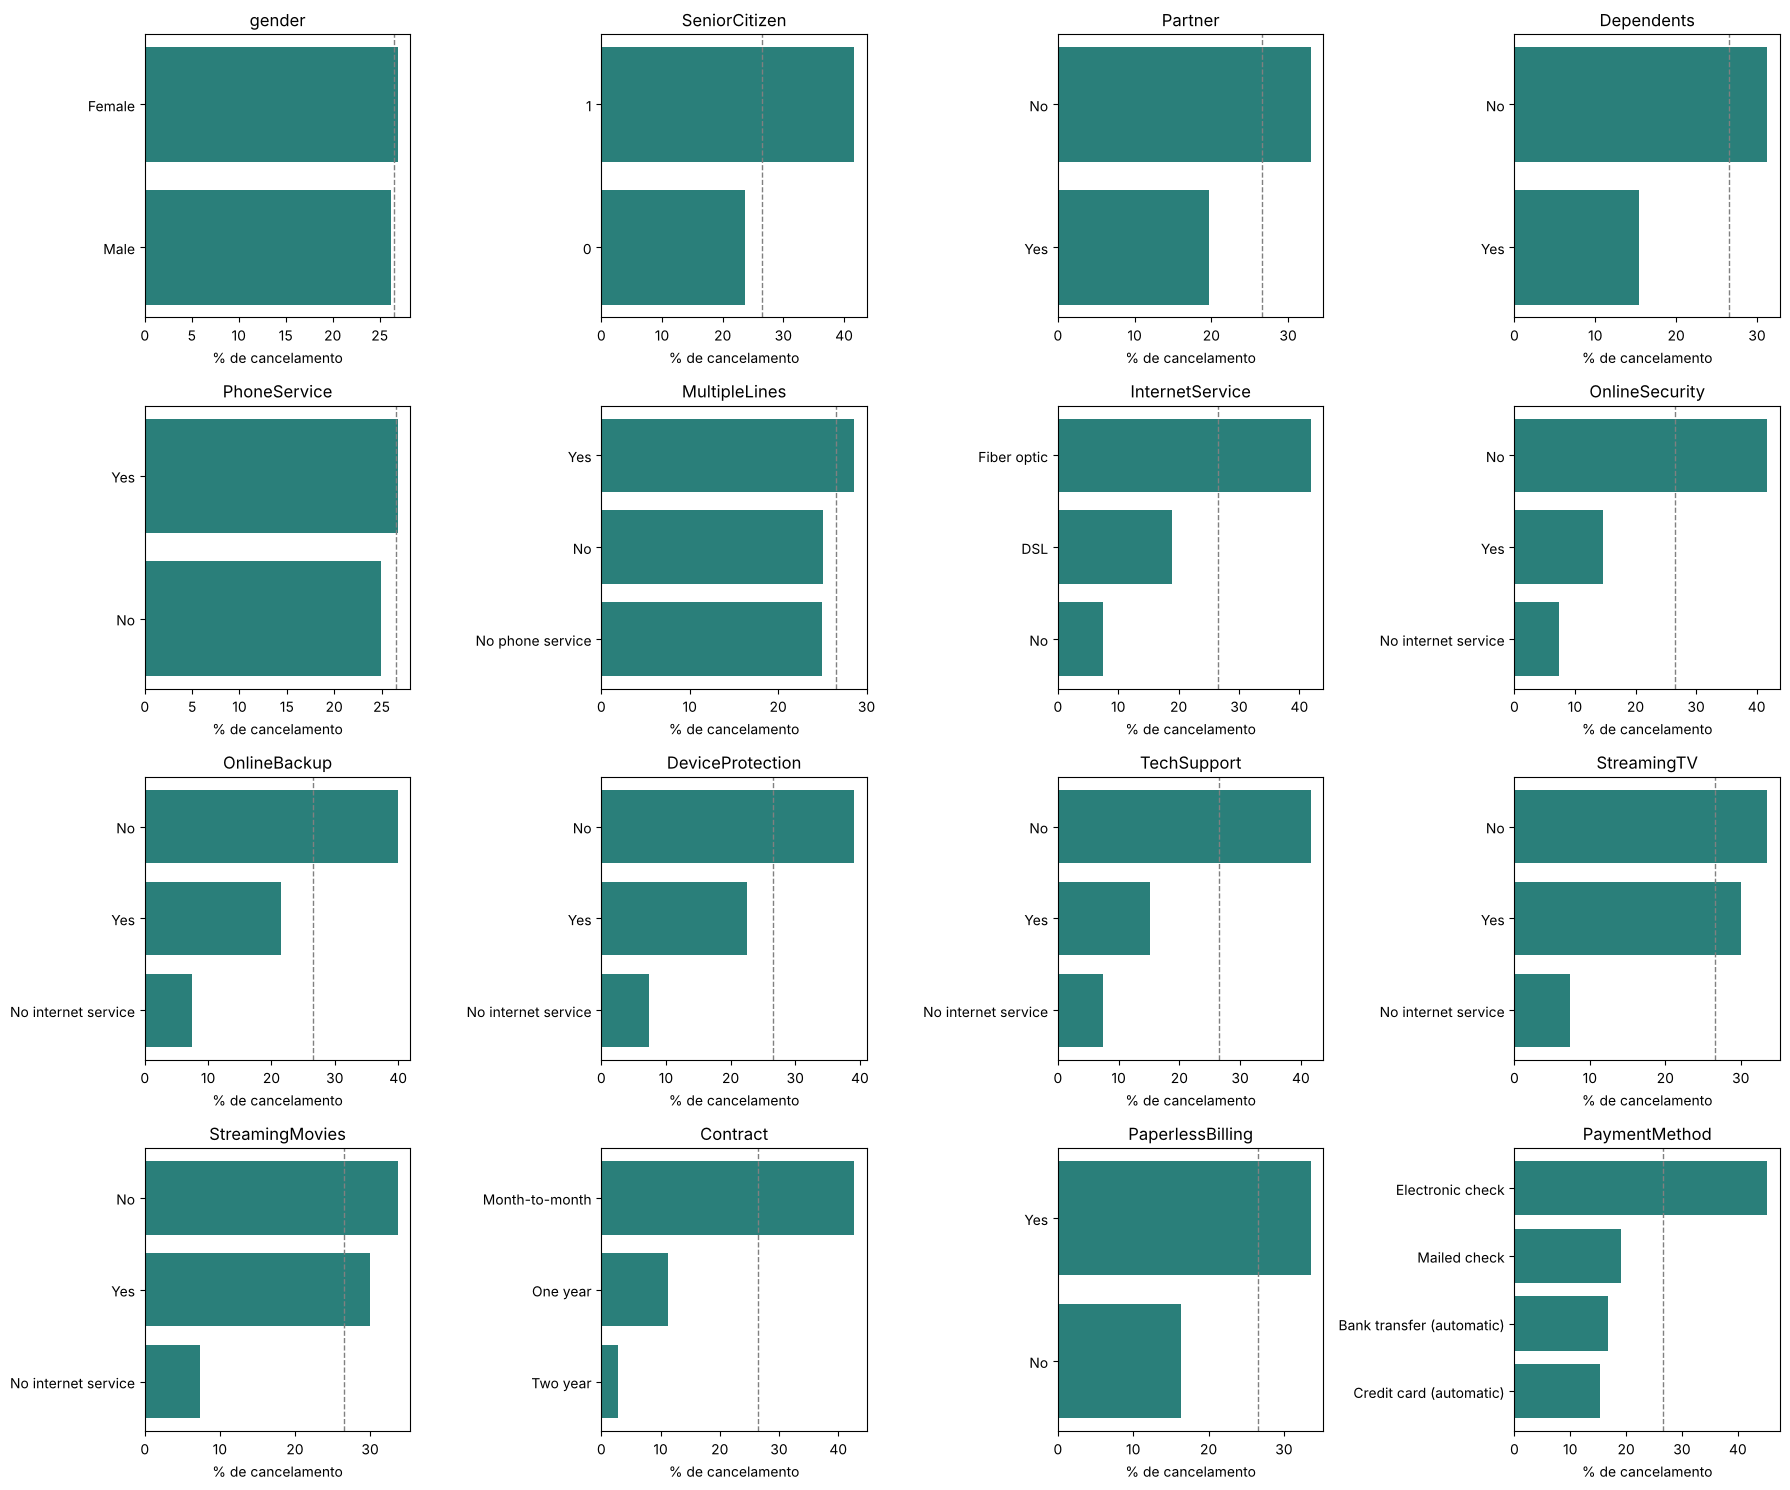

        variável  categorias  menor taxa (%)  maior taxa (%)  amplitude (p.p.)
        Contract           3             2.8            42.7              39.9
 InternetService           3             7.4            41.9              34.5
  OnlineSecurity           3             7.4            41.8              34.4
     TechSupport           3             7.4            41.6              34.2
    OnlineBackup           3             7.4            39.9              32.5
DeviceProtection           3             7.4            39.1              31.7
   PaymentMethod           4            15.2            45.3              30.0
 StreamingMovies           3             7.4            33.7              26.3
     StreamingTV           3             7.4            33.5              26.1
   SeniorCitizen           2            23.6            41.7              18.1
PaperlessBilling           2            16.3            33.6              17.2
      Dependents           2            15.5        

In [6]:
CATEGORICAS = [c for c in bruto.columns if c not in ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
alvo = (bruto["Churn"] == "Yes").astype(int)
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, c in zip(axes.flat, CATEGORICAS):
    taxa = alvo.groupby(bruto[c]).mean().sort_values() * 100
    ax.barh(taxa.index.astype(str), taxa.values, color="#2a7f7a")
    ax.axvline(alvo.mean() * 100, color="grey", ls="--", lw=1)
    ax.set_title(c); ax.set_xlabel("% de cancelamento")
for ax in axes.flat[len(CATEGORICAS):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("figuras/01_taxa_categoricas.png", dpi=150); plt.show()

resumo_cat = []
for c in CATEGORICAS:
    t = alvo.groupby(bruto[c]).mean() * 100
    resumo_cat.append({"variável": c, "categorias": len(t), "menor taxa (%)": t.min().round(1), "maior taxa (%)": t.max().round(1),
                       "amplitude (p.p.)": (t.max() - t.min()).round(1)})
print(pd.DataFrame(resumo_cat).sort_values("amplitude (p.p.)", ascending=False).to_string(index=False))

A linha tracejada é a taxa geral (26,5%). Contrato mensal, internet por fibra óptica, pagamento por boleto eletrônico (*electronic check*) e ausência de serviços de segurança e suporte concentram os cancelamentos; o gênero praticamente não diferencia os grupos.

### 3d. Variáveis numéricas

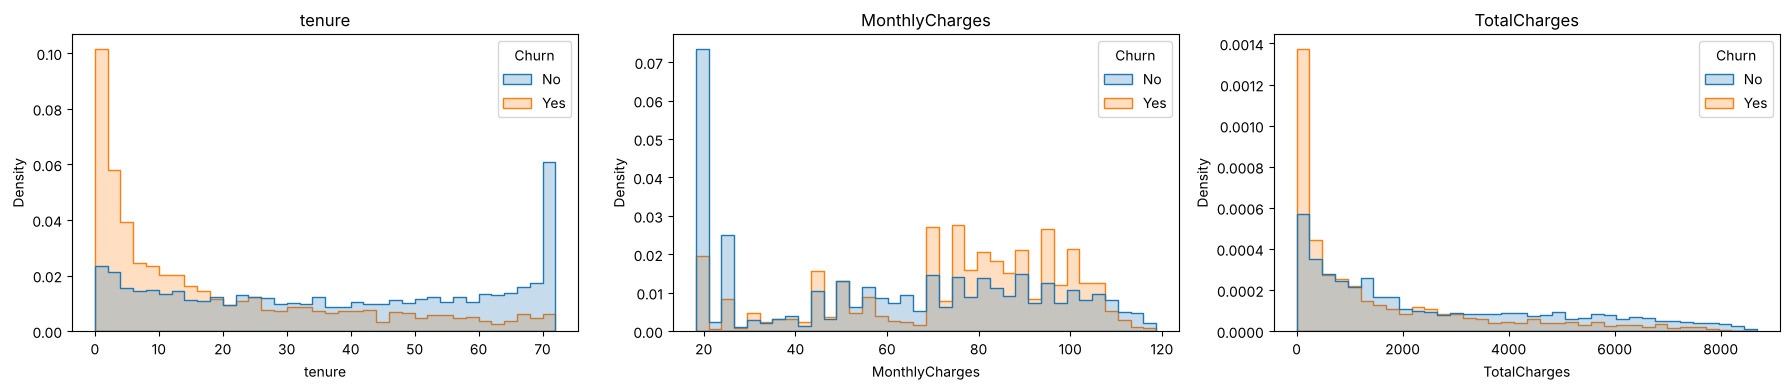

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0           64.43       1679.52
Yes      10.0           79.65        703.55

Correlação de Pearson:
                 tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00

Valores fora de Q1 − 1,5·IQR e Q3 + 1,5·IQR:
 tenure            0
MonthlyCharges    0
TotalCharges      0


In [7]:
num = bruto[["tenure", "MonthlyCharges"]].copy()
num["TotalCharges"] = tc.fillna(0)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, num.columns):
    sns.histplot(x=num[c], hue=bruto["Churn"], bins=36, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.savefig("figuras/02_numericas.png", dpi=150); plt.show()
print(num.groupby(bruto["Churn"]).median().round(2))
print("\nCorrelação de Pearson:\n", num.corr().round(2))
q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
print("\nValores fora de Q1 − 1,5·IQR e Q3 + 1,5·IQR:\n", ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum().to_string())

Quem cancela tem tempo de casa (`tenure`) muito menor e mensalidade maior. `TotalCharges` é altamente correlacionada com `tenure` (≈ mensalidade × meses). Não há valores extremos pela regra do intervalo interquartil, então nenhuma observação é excluída.

## 4. Divisão treino / validação / teste

A divisão é **estratificada** (mantém 26,5% de cancelamentos em cada parte) e vem **antes de qualquer ajuste**:
- **Treino (60%)**: ajuste dos pesos e do pré-processamento.
- **Validação (20%)**: parada antecipada, comparação de configurações e escolha do limiar de decisão.
- **Teste (20%)**: usado **uma única vez**, na seção 11.

A limpeza abaixo só aplica regras fixas (não aprende nada dos dados), então pode ser feita antes da divisão.

In [8]:
BINARIAS = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
ORDINAL = ["Contract"]                                    # mensal < 1 ano < 2 anos
NOMINAIS = [c for c in CATEGORICAS if c not in BINARIAS + ORDINAL]

def limpa(df):
    X = df.drop(columns=["customerID", "Churn"]).copy()
    X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce").fillna(0)   # tenure 0 -> nada faturado
    X["gender"] = (X["gender"] == "Female").astype(int)
    for c in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        X[c] = (X[c] == "Yes").astype(int)
    return X

X = limpa(bruto)
y = (bruto["Churn"] == "Yes").astype(int).values
X_dev, X_te, y_dev, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
X_tr, X_va, y_tr, y_va = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEMENTE)
for nome, yy in [("treino", y_tr), ("validação", y_va), ("teste", y_te)]:
    print(f"{nome:10s} {len(yy):5d} clientes | cancelamento {yy.mean() * 100:.1f}%")
print("\nTipos: binárias", len(BINARIAS), "| ordinal", len(ORDINAL), "| nominais", len(NOMINAIS), "| numéricas", len(NUMERICAS))

treino      4225 clientes | cancelamento 26.5%
validação   1409 clientes | cancelamento 26.5%
teste       1409 clientes | cancelamento 26.5%

Tipos: binárias 6 | ordinal 1 | nominais 9 | numéricas 3


## 5. Pré-processamento ajustado só no treino

| Tipo | Variáveis | Tratamento |
|---|---|---|
| Numéricas | `tenure`, `MonthlyCharges`, `TotalCharges` | padronização (`StandardScaler`) |
| Binárias | gênero, idoso, parceiro, dependentes, telefone, fatura digital | 0/1 |
| Ordinal | `Contract` (mensal < 1 ano < 2 anos) | código 0/1/2 padronizado |
| Nominais | internet, serviços adicionais, forma de pagamento… | 0/1 por categoria (`OneHotEncoder`) |

A padronização deixa as entradas na mesma escala, o que acelera e estabiliza o gradiente da rede. O `ColumnTransformer` é ajustado (`fit`) apenas no treino e aplicado (`transform`) na validação e no teste, sem vazamento de informação.

In [9]:
def cria_pre():
    return ColumnTransformer([
        ("numericas", StandardScaler(), NUMERICAS),
        ("contrato", Pipeline([("ord", OrdinalEncoder(categories=[["Month-to-month", "One year", "Two year"]])),
                               ("esc", StandardScaler())]), ORDINAL),
        ("binarias", "passthrough", BINARIAS),
        ("nominais", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAIS)])

pre = cria_pre()
A_tr = pre.fit_transform(X_tr).astype("float32")
A_va = pre.transform(X_va).astype("float32")
A_te = pre.transform(X_te).astype("float32")
nomes = pre.get_feature_names_out()
print("Atributos de entrada:", A_tr.shape[1])

Atributos de entrada: 38


## 6. Modelos de referência

Antes da rede, dois modelos simples dão a régua:
- **Classe majoritária**: prevê sempre “não cancela”.
- **Regressão logística** com pesos de classe balanceados e força de regularização escolhida por validação cruzada no treino.

Funções auxiliares calculam todas as métricas para um limiar de decisão.

In [10]:
def metricas(y, p, limiar=0.5):
    pred = (p >= limiar).astype(int)
    return {"acurácia": accuracy_score(y, pred), "precisão": precision_score(y, pred, zero_division=0),
            "revocação": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p)}

maj = DummyClassifier(strategy="most_frequent").fit(A_tr, y_tr)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
melhor_c, melhor_ap = None, -1
for C in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    ap = np.mean([average_precision_score(y_tr[b], LogisticRegression(C=C, class_weight="balanced", max_iter=3000)
                  .fit(A_tr[a], y_tr[a]).predict_proba(A_tr[b])[:, 1]) for a, b in skf.split(A_tr, y_tr)])
    if ap > melhor_ap: melhor_c, melhor_ap = C, ap
logistica = LogisticRegression(C=melhor_c, class_weight="balanced", max_iter=3000).fit(A_tr, y_tr)
p_va_log = logistica.predict_proba(A_va)[:, 1]
ref = pd.DataFrame({"Classe majoritária": metricas(y_va, maj.predict_proba(A_va)[:, 1]),
                    f"Regressão logística (C={melhor_c})": metricas(y_va, p_va_log)}).T
print("Validação, limiar 0,5:\n", ref.round(4).to_string())

Validação, limiar 0,5:
                             acurácia  precisão  revocação      F1  ROC-AUC  PR-AUC
Classe majoritária            0.7346    0.0000     0.0000  0.0000   0.5000  0.2654
Regressão logística (C=10)    0.7445    0.5122     0.7861  0.6203   0.8369  0.6433


## 7. MLP inicial, sem regularização

Primeira rede: duas camadas ocultas (64 e 32 neurônios, ReLU), saída sigmoide e entropia cruzada binária, sem Dropout, sem L2, sem pesos de classe e com 200 épocas fixas. Serve para observar o comportamento de uma rede sem nenhum controle de sobreajuste.

Tempo: 42 s | melhor época (menor perda de validação): 5
acurácia     0.7580
precisão     0.5495
revocação    0.4893
F1           0.5177
ROC-AUC      0.7744
PR-AUC       0.5213


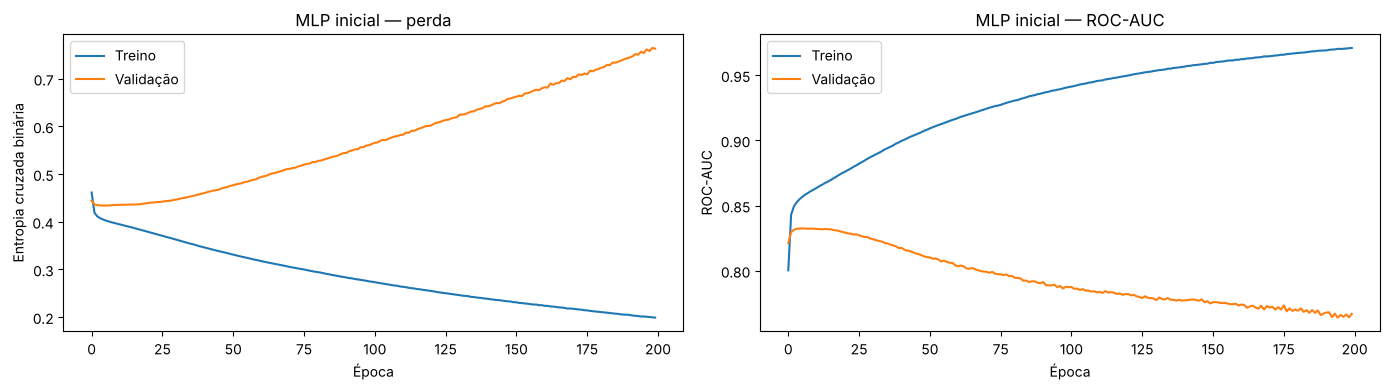

In [11]:
def cria_rede(n, neuronios=(64, 32), dropout=0.0, l2=0.0, lr=1e-3):
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([keras.Input(shape=(n,))])
    for u in neuronios:
        m.add(layers.Dense(u, activation="relu", kernel_initializer="he_normal", kernel_regularizer=reg))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc")])
    return m

def pesos_balanceados(y):
    w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y)
    return {0: w[0], 1: w[1]}

keras.utils.set_random_seed(SEMENTE)
rede0 = cria_rede(A_tr.shape[1])
t0 = time.time()
h0 = rede0.fit(A_tr, y_tr, validation_data=(A_va, y_va), epochs=200, batch_size=64, verbose=0)
p_va_0 = rede0.predict(A_va, verbose=0).ravel()
print(f"Tempo: {time.time() - t0:.0f} s | melhor época (menor perda de validação): {np.argmin(h0.history['val_loss']) + 1}")
print(pd.Series(metricas(y_va, p_va_0)).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h0.history["loss"], label="Treino"); axes[0].plot(h0.history["val_loss"], label="Validação")
axes[0].set(xlabel="Época", ylabel="Entropia cruzada binária", title="MLP inicial — perda"); axes[0].legend()
axes[1].plot(h0.history["auc"], label="Treino"); axes[1].plot(h0.history["val_auc"], label="Validação")
axes[1].set(xlabel="Época", ylabel="ROC-AUC", title="MLP inicial — ROC-AUC"); axes[1].legend()
plt.tight_layout(); plt.savefig("figuras/03_mlp_inicial.png", dpi=150); plt.show()

A perda de treino cai continuamente, enquanto a de validação atinge o mínimo cedo e depois sobe: a rede passa a memorizar o treino (sobreajuste). As seções seguintes combatem isso com regularização, parada antecipada e escolha de hiperparâmetros.

## 8. Busca aleatória de hiperparâmetros com validação cruzada

A busca aleatória (*random search*) sorteia combinações do espaço abaixo e avalia cada uma por **validação cruzada estratificada de 3 dobras no treino** (a validação e o teste não participam). Em cada dobra, 15% da parte de ajuste são separados para a parada antecipada.

Critério: **PR-AUC** (área sob a curva precisão-revocação), mais informativa que a acurácia e que a ROC-AUC quando a classe positiva é minoritária.

| Hiperparâmetro | Valores |
|---|---|
| Neurônios por camada | (16), (32), (64), (32, 16), (64, 32), (128, 64) |
| Dropout | 0; 0,2; 0,4 |
| L2 | 0; 10⁻⁴; 10⁻³ |
| Taxa de aprendizado | 3×10⁻⁴; 10⁻³; 3×10⁻³ |
| Tamanho do lote | 32; 64; 128 |
| Pesos de classe | nenhum; balanceados |

In [12]:
ESPACO = dict(neuronios=[(16,), (32,), (64,), (32, 16), (64, 32), (128, 64)], dropout=[0.0, 0.2, 0.4],
              l2=[0.0, 1e-4, 1e-3], lr=[3e-4, 1e-3, 3e-3], batch=[32, 64, 128], pesos=[False, True])
N_COMBINACOES = 16
sorteio = random.Random(SEMENTE)
candidatos = [{k: sorteio.choice(v) for k, v in ESPACO.items()} for _ in range(N_COMBINACOES)]
dobras = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE).split(X_tr, y_tr))

def parada():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)]

def avalia_cv(c):
    aps, aucs, epocas = [], [], []
    for a, b in dobras:
        p_ = cria_pre(); Aa = p_.fit_transform(X_tr.iloc[a]).astype("float32"); Ab = p_.transform(X_tr.iloc[b]).astype("float32")
        ia, iv = train_test_split(np.arange(len(a)), test_size=0.15, stratify=y_tr[a], random_state=SEMENTE)
        keras.utils.set_random_seed(SEMENTE)
        m = cria_rede(Aa.shape[1], c["neuronios"], c["dropout"], c["l2"], c["lr"])
        h = m.fit(Aa[ia], y_tr[a][ia], validation_data=(Aa[iv], y_tr[a][iv]), epochs=300, batch_size=c["batch"],
                  class_weight=pesos_balanceados(y_tr[a][ia]) if c["pesos"] else None, callbacks=parada(), verbose=0)
        p = m.predict(Ab, verbose=0).ravel()
        aps.append(average_precision_score(y_tr[b], p)); aucs.append(roc_auc_score(y_tr[b], p)); epocas.append(len(h.history["loss"]))
    return np.mean(aps), np.std(aps), np.mean(aucs), np.mean(epocas)

t0 = time.time(); linhas_busca = []
for k, c in enumerate(candidatos):
    ap, ap_dp, auc, ep = avalia_cv(c)
    linhas_busca.append({"id": k, **{kk: str(v) for kk, v in c.items()}, "PR-AUC (CV)": ap, "dp": ap_dp, "ROC-AUC (CV)": auc, "épocas": ep})
    print(f"{k:2d} {c}  PR-AUC = {ap:.4f} ± {ap_dp:.4f}")
busca = pd.DataFrame(linhas_busca).sort_values("PR-AUC (CV)", ascending=False)
busca.to_csv("busca_hiperparametros.csv", index=False)
print(f"\nTempo da busca: {(time.time() - t0) / 60:.1f} min")
print(busca.head(6).round(4).to_string(index=False))
HP = candidatos[int(busca.iloc[0]["id"])]
print("\nConfiguração escolhida:", HP)
print("Diferença para a 2ª colocada: %.4f (desvio entre dobras da 1ª: %.4f)" % (busca.iloc[0]["PR-AUC (CV)"] - busca.iloc[1]["PR-AUC (CV)"], busca.iloc[0]["dp"]))

 0 {'neuronios': (128, 64), 'dropout': 0.0, 'l2': 0.0, 'lr': 0.003, 'batch': 64, 'pesos': False}  PR-AUC = 0.6532 ± 0.0074


 1 {'neuronios': (32,), 'dropout': 0.0, 'l2': 0.001, 'lr': 0.0003, 'batch': 128, 'pesos': False}  PR-AUC = 0.6600 ± 0.0097


 2 {'neuronios': (64, 32), 'dropout': 0.2, 'l2': 0.0, 'lr': 0.0003, 'batch': 32, 'pesos': False}  PR-AUC = 0.6586 ± 0.0096


 3 {'neuronios': (32,), 'dropout': 0.4, 'l2': 0.001, 'lr': 0.0003, 'batch': 128, 'pesos': False}  PR-AUC = 0.6607 ± 0.0113


 4 {'neuronios': (128, 64), 'dropout': 0.4, 'l2': 0.001, 'lr': 0.003, 'batch': 64, 'pesos': False}  PR-AUC = 0.6603 ± 0.0082


 5 {'neuronios': (32, 16), 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.0003, 'batch': 32, 'pesos': True}  PR-AUC = 0.6545 ± 0.0148


... (6 outputs left out)

12 {'neuronios': (32, 16), 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.0003, 'batch': 64, 'pesos': True}  PR-AUC = 0.6544 ± 0.0134


13 {'neuronios': (32,), 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.003, 'batch': 128, 'pesos': False}  PR-AUC = 0.6539 ± 0.0143


14 {'neuronios': (64, 32), 'dropout': 0.4, 'l2': 0.0, 'lr': 0.003, 'batch': 128, 'pesos': False}  PR-AUC = 0.6627 ± 0.0095


15 {'neuronios': (32,), 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'batch': 128, 'pesos': False}  PR-AUC = 0.6538 ± 0.0138

Tempo da busca: 10.2 min
 id neuronios dropout     l2     lr batch pesos  PR-AUC (CV)     dp  ROC-AUC (CV)   épocas
 14  (64, 32)     0.4    0.0  0.003   128 False       0.6627 0.0095        0.8452  35.3333
  3     (32,)     0.4  0.001 0.0003   128 False       0.6607 0.0113        0.8446 238.3333
  8     (16,)     0.4 0.0001  0.003    32  True       0.6607 0.0119        0.8430  39.3333
  4 (128, 64)     0.4  0.001  0.003    64 False       0.6603 0.0082        0.8412  48.3333
  1     (32,)     0.0  0.001 0.0003   128 False       0.6600 0.0097        0.8436 255.6667
  2  (64, 32)     0.2    0.0 0.0003    32 False       0.6586 0.0096        0.8424  64.0000

Configuração escolhida: {'neuronios': (64, 32), 'dropout': 0.4, 'l2': 0.0, 'lr': 0.003, 'batch': 128, 'pesos': False}
Diferença para a 2ª colocada: 0.0020 (desvio entre dobras da 1ª: 0.0095)


## 9. Contribuição de cada técnica (ablação)

Partindo da configuração escolhida, cada técnica é retirada isoladamente e a rede é treinada com **5 sementes**, avaliando-se na validação. A mesma semente é usada em todas as variantes (comparação pareada). Assim, a diferença de desempenho mede a contribuição daquela técnica, e o desvio entre sementes mostra quanto do resultado é variação aleatória.

In [13]:
SEMENTES = range(5)
def treina(c, sementes, A=A_tr, yy=y_tr, Av=A_va, yv=y_va, parar=True, epocas=300):
    previsoes, historicos, modelos = [], [], []
    for s in sementes:
        keras.utils.set_random_seed(s)
        m = cria_rede(A.shape[1], c["neuronios"], c["dropout"], c["l2"], c["lr"])
        h = m.fit(A, yy, validation_data=(Av, yv), epochs=epocas, batch_size=c["batch"],
                  class_weight=pesos_balanceados(yy) if c["pesos"] else None,
                  callbacks=parada() if parar else [], verbose=0)
        previsoes.append(m.predict(Av, verbose=0).ravel()); historicos.append(h); modelos.append(m)
    return previsoes, historicos, modelos

variantes = {"Configuração escolhida": (HP, True),
             "Sem Dropout": ({**HP, "dropout": 0.0}, True),
             "Sem L2": ({**HP, "l2": 0.0}, True),
             "Com L2 (10⁻³)": ({**HP, "l2": 1e-3}, True),
             "Sem pesos de classe": ({**HP, "pesos": False}, True),
             "Com pesos de classe": ({**HP, "pesos": True}, True),
             "Sem EarlyStopping (200 épocas)": (HP, False)}
linhas_abl = []
for nome, (c, parar) in variantes.items():
    if nome == "Com pesos de classe" and HP["pesos"]: continue
    if nome == "Sem pesos de classe" and not HP["pesos"]: continue
    if nome == "Sem Dropout" and HP["dropout"] == 0: continue
    if nome == "Sem L2" and HP["l2"] == 0: continue
    if nome == "Com L2 (10⁻³)" and HP["l2"] > 0: continue
    t0 = time.time()
    prevs, hists, _ = treina(c, SEMENTES, parar=parar, epocas=300 if parar else 200)
    for s, p in zip(SEMENTES, prevs):
        linhas_abl.append({"Variante": nome, "Semente": s, "Épocas": len(hists[s].history["loss"]), **metricas(y_va, p)})
    print(f"{nome}: {time.time() - t0:.0f} s")
abl = pd.DataFrame(linhas_abl)
abl.to_csv("ablacao.csv", index=False)
tab_abl = abl.groupby("Variante", sort=False)[["Épocas", "PR-AUC", "ROC-AUC", "F1", "revocação", "precisão"]].agg(["mean", "std"])
print(tab_abl.round(4).to_string())

Configuração escolhida: 35 s


Sem Dropout: 23 s


Com L2 (10⁻³): 60 s


Com pesos de classe: 33 s


Sem EarlyStopping (200 épocas): 157 s
                               Épocas           PR-AUC         ROC-AUC              F1         revocação         precisão        
                                 mean      std    mean     std    mean     std    mean     std      mean     std     mean     std
Variante                                                                                                                         
Configuração escolhida           37.4   5.5946  0.6358  0.0053  0.8331  0.0008  0.5541  0.0180    0.4663  0.0294   0.6846  0.0142
Sem Dropout                      23.2   1.6432  0.6282  0.0066  0.8302  0.0013  0.5813  0.0124    0.5235  0.0322   0.6557  0.0196
Com L2 (10⁻³)                    70.4   7.0214  0.6396  0.0022  0.8339  0.0010  0.5692  0.0180    0.4952  0.0313   0.6710  0.0087
Com pesos de classe              31.8  11.8195  0.6333  0.0037  0.8308  0.0020  0.6196  0.0075    0.7497  0.0106   0.5282  0.0128
Sem EarlyStopping (200 épocas)  200.0   0.0000  0.59

## 10. Modelo final: conjunto de 5 redes e escolha do limiar

O modelo final é a **média das probabilidades de 5 redes** com a configuração escolhida (sementes 0 a 4), o que reduz a variação causada pela inicialização aleatória.

O limiar de 0,5 não é obrigatório: em retenção de clientes, deixar de identificar quem vai sair (falso negativo) costuma custar mais do que abordar quem ficaria (falso positivo). O limiar é escolhido **na validação**, maximizando o F1, e depois apenas aplicado ao teste.

Limiar escolhido na validação — MLP: 0.35 | regressão logística: 0.62


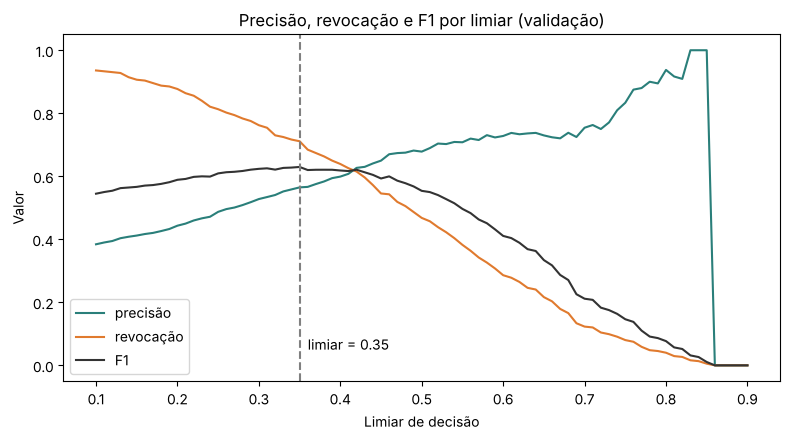

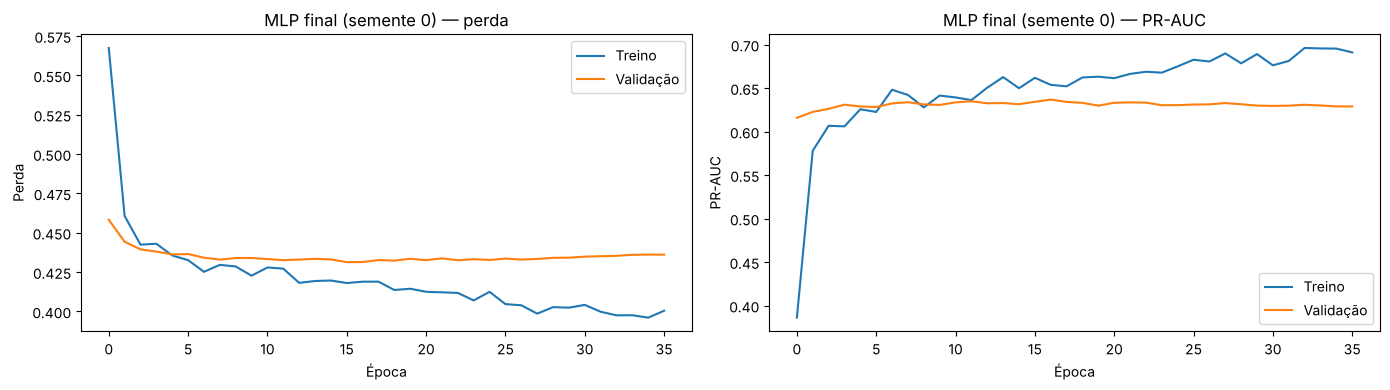

Épocas treinadas por semente: [36, 33, 37, 34, 47]


In [14]:
prev_final, hist_final, redes_finais = treina(HP, SEMENTES)
p_va_mlp = np.mean(prev_final, axis=0)

limiares = np.round(np.arange(0.10, 0.91, 0.01), 2)
curva = pd.DataFrame([{"limiar": t, **metricas(y_va, p_va_mlp, t)} for t in limiares])
LIMIAR = float(curva.loc[curva["F1"].idxmax(), "limiar"])
curva_log = pd.DataFrame([{"limiar": t, **metricas(y_va, p_va_log, t)} for t in limiares])
LIMIAR_LOG = float(curva_log.loc[curva_log["F1"].idxmax(), "limiar"])
print(f"Limiar escolhido na validação — MLP: {LIMIAR:.2f} | regressão logística: {LIMIAR_LOG:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for m_, cor in [("precisão", "#2a7f7a"), ("revocação", "#e07a2e"), ("F1", "#333333")]:
    ax.plot(curva["limiar"], curva[m_], label=m_, color=cor)
ax.axvline(LIMIAR, ls="--", color="grey"); ax.text(LIMIAR + 0.01, 0.05, f"limiar = {LIMIAR:.2f}")
ax.set(xlabel="Limiar de decisão", ylabel="Valor", title="Precisão, revocação e F1 por limiar (validação)"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/04_limiar.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
h = hist_final[0].history
axes[0].plot(h["loss"], label="Treino"); axes[0].plot(h["val_loss"], label="Validação")
axes[0].set(xlabel="Época", ylabel="Perda", title="MLP final (semente 0) — perda"); axes[0].legend()
axes[1].plot(h["pr_auc"], label="Treino"); axes[1].plot(h["val_pr_auc"], label="Validação")
axes[1].set(xlabel="Época", ylabel="PR-AUC", title="MLP final (semente 0) — PR-AUC"); axes[1].legend()
plt.tight_layout(); plt.savefig("figuras/05_mlp_final_curvas.png", dpi=150); plt.show()
print("Épocas treinadas por semente:", [len(x.history["loss"]) for x in hist_final])

## 11. Avaliação final no conjunto de teste

Única utilização do teste. Todos os modelos usam o limiar escolhido na validação (0,5 para a classe majoritária).

In [15]:
p_te_mlp = np.mean([m.predict(A_te, verbose=0).ravel() for m in redes_finais], axis=0)   # as 5 redes da seção 10
p_te_log = logistica.predict_proba(A_te)[:, 1]
p_te_0 = rede0.predict(A_te, verbose=0).ravel()

teste = pd.DataFrame({
    "Classe majoritária": metricas(y_te, maj.predict_proba(A_te)[:, 1]),
    "Regressão logística": metricas(y_te, p_te_log, LIMIAR_LOG),
    "MLP inicial (limiar 0,5)": metricas(y_te, p_te_0),
    "MLP final (limiar 0,5)": metricas(y_te, p_te_mlp),
    f"MLP final (limiar {LIMIAR:.2f})": metricas(y_te, p_te_mlp, LIMIAR)}).T
teste.to_csv("resultados_teste.csv")
print(teste.round(4).to_string())

cm = confusion_matrix(y_te, (p_te_mlp >= LIMIAR).astype(int))
print("\nMatriz de confusão (MLP final):\n", pd.DataFrame(cm, index=["real: fica", "real: cancela"], columns=["prev.: fica", "prev.: cancela"]))
print("Brier score — MLP: %.4f | logística: %.4f" % (brier_score_loss(y_te, p_te_mlp), brier_score_loss(y_te, p_te_log)))

                          acurácia  precisão  revocação      F1  ROC-AUC  PR-AUC
Classe majoritária          0.7346    0.0000     0.0000  0.0000   0.5000  0.2654
Regressão logística         0.7700    0.5527     0.7005  0.6179   0.8420  0.6272
MLP inicial (limiar 0,5)    0.7608    0.5533     0.5134  0.5326   0.7863  0.5405
MLP final (limiar 0,5)      0.7991    0.6691     0.4813  0.5599   0.8408  0.6351
MLP final (limiar 0.35)     0.7622    0.5411     0.6872  0.6054   0.8408  0.6351

Matriz de confusão (MLP final):
                prev.: fica  prev.: cancela
real: fica             817             218
real: cancela          117             257
Brier score — MLP: 0.1383 | logística: 0.1681


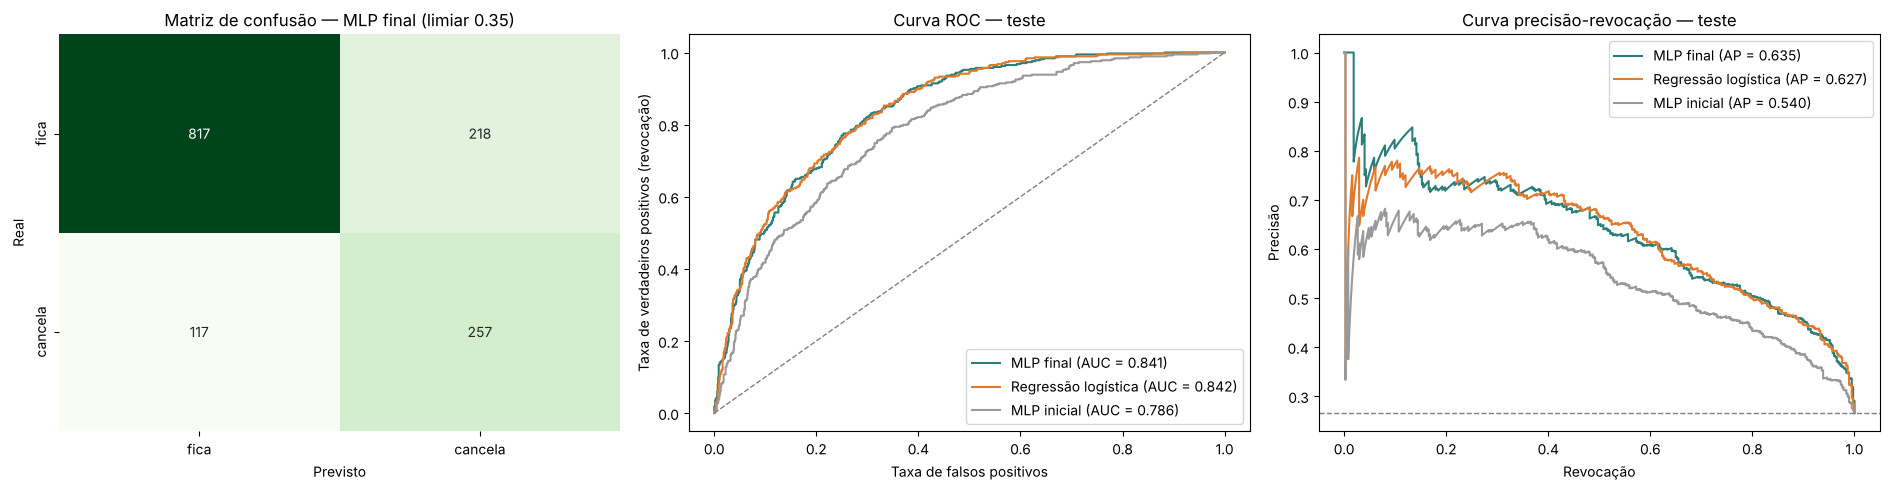

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[0],
            xticklabels=["fica", "cancela"], yticklabels=["fica", "cancela"])
axes[0].set(xlabel="Previsto", ylabel="Real", title=f"Matriz de confusão — MLP final (limiar {LIMIAR:.2f})")
for p, nome, cor in [(p_te_mlp, "MLP final", "#2a7f7a"), (p_te_log, "Regressão logística", "#e07a2e"), (p_te_0, "MLP inicial", "#999999")]:
    fpr, tpr, _ = roc_curve(y_te, p); axes[1].plot(fpr, tpr, color=cor, label=f"{nome} (AUC = {roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p); axes[2].plot(rc, pr, color=cor, label=f"{nome} (AP = {average_precision_score(y_te, p):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey", lw=1)
axes[1].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (revocação)", title="Curva ROC — teste"); axes[1].legend(loc="lower right")
axes[2].axhline(y_te.mean(), ls="--", color="grey", lw=1)
axes[2].set(xlabel="Revocação", ylabel="Precisão", title="Curva precisão-revocação — teste"); axes[2].legend(loc="upper right")
plt.tight_layout(); plt.savefig("figuras/06_teste.png", dpi=150); plt.show()

## 12. Análise dos erros e importância das variáveis

### 12a. Desempenho por tipo de contrato e por tempo de casa (teste)

In [17]:
analise = X_te[["Contract", "tenure"]].copy()
analise["real"] = y_te; analise["prev"] = (p_te_mlp >= LIMIAR).astype(int)
analise["faixa de tenure"] = pd.cut(analise["tenure"], [-1, 12, 24, 48, 72], labels=["0–12", "13–24", "25–48", "49–72"])
def resumo(g):
    return pd.Series({"clientes": len(g), "taxa real (%)": g["real"].mean() * 100,
                      "revocação": recall_score(g["real"], g["prev"], zero_division=0),
                      "precisão": precision_score(g["real"], g["prev"], zero_division=0),
                      "falsos positivos": int(((g["prev"] == 1) & (g["real"] == 0)).sum()),
                      "falsos negativos": int(((g["prev"] == 0) & (g["real"] == 1)).sum())})
print(analise.groupby("Contract").apply(resumo).round(3).to_string(), "\n")
print(analise.groupby("faixa de tenure", observed=True).apply(resumo).round(3).to_string())

                clientes  taxa real (%)  revocação  precisão  falsos positivos  falsos negativos
Contract                                                                                        
Month-to-month     773.0         42.561      0.769     0.549             208.0              76.0
One year           300.0         12.000      0.111     0.286              10.0              32.0
Two year           336.0          2.679      0.000     0.000               0.0               9.0 

                 clientes  taxa real (%)  revocação  precisão  falsos positivos  falsos negativos
faixa de tenure                                                                                  
0–12                449.0         47.884      0.772     0.619             102.0              49.0
13–24               206.0         29.126      0.850     0.472              57.0               9.0
25–48               304.0         21.053      0.531     0.442              43.0              30.0
49–72               450

### 12b. Importância por permutação (validação)

Cada variável original é embaralhada (todas as suas colunas codificadas juntas) e mede-se a queda de PR-AUC do conjunto de redes na validação. Quanto maior a queda, mais o modelo depende da variável. Repetido 10 vezes por variável.

        variável  queda de PR-AUC     dp
          tenure           0.0763 0.0152
        Contract           0.0650 0.0117
 InternetService           0.0441 0.0102
    TotalCharges           0.0227 0.0129
  MonthlyCharges           0.0160 0.0063
     TechSupport           0.0145 0.0070
  OnlineSecurity           0.0093 0.0065
 StreamingMovies           0.0090 0.0034
   PaymentMethod           0.0067 0.0050
PaperlessBilling           0.0063 0.0041
   MultipleLines           0.0061 0.0060
      Dependents           0.0024 0.0039
   SeniorCitizen           0.0019 0.0022
DeviceProtection           0.0012 0.0026
    OnlineBackup          -0.0002 0.0043
          gender          -0.0003 0.0008
         Partner          -0.0005 0.0019
     StreamingTV          -0.0019 0.0047
    PhoneService          -0.0020 0.0016


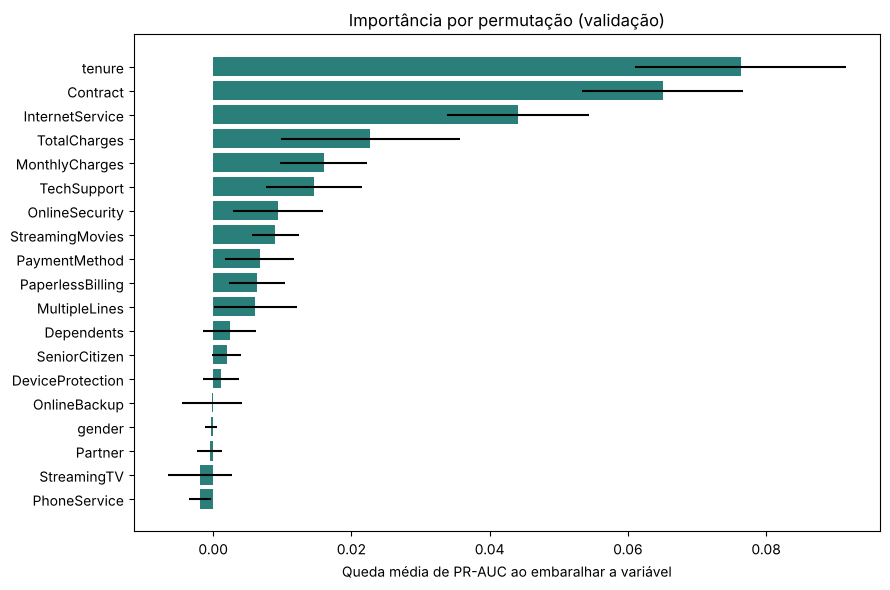

In [18]:
def prob_conjunto(A):
    return np.mean([m.predict(A, verbose=0, batch_size=2048).ravel() for m in redes_finais], axis=0)
base_ap = average_precision_score(y_va, prob_conjunto(A_va))
grupos = {v: [i for i, n in enumerate(nomes) if n.split("__")[1] == v or n.split("__")[1].startswith(v + "_")]
          for v in NUMERICAS + ORDINAL + BINARIAS + NOMINAIS}
rng = np.random.default_rng(SEMENTE); imp = []
for v, idx in grupos.items():
    quedas = []
    for _ in range(10):
        Ap = A_va.copy(); Ap[:, idx] = Ap[rng.permutation(len(Ap))][:, idx]
        quedas.append(base_ap - average_precision_score(y_va, prob_conjunto(Ap)))
    imp.append({"variável": v, "queda de PR-AUC": np.mean(quedas), "dp": np.std(quedas)})
imp = pd.DataFrame(imp).sort_values("queda de PR-AUC", ascending=False)
print(imp.round(4).to_string(index=False))
plt.figure(figsize=(9, 6))
plt.barh(imp["variável"][::-1], imp["queda de PR-AUC"][::-1], xerr=imp["dp"][::-1], color="#2a7f7a")
plt.xlabel("Queda média de PR-AUC ao embaralhar a variável"); plt.title("Importância por permutação (validação)")
plt.tight_layout(); plt.savefig("figuras/07_importancia.png", dpi=150); plt.show()

## 13. Síntese

Os números finais, a discussão e as limitações estão no relatório. Os arquivos gerados por este notebook (`figuras/`, `busca_hiperparametros.csv`, `ablacao.csv`, `resultados_teste.csv`) são a base de todas as tabelas e figuras do relatório.